# 01 — The Kritchman & Nadler estimator, deconstructed

> **Prerequisite:** the shared theory in [`README.md`](README.md) — the C-KLT / MR-KLT
> front-end, the spiked-covariance model, and the RMT background (Marchenko–Pastur, BBP,
> Tracy–Widom). This notebook assumes it and does not repeat it.

Kritchman & Nadler (2009) answer *"how many signals are in this covariance matrix?"* without
any prior knowledge of the signals or the array. Earlier information-theoretic criteria (AIC,
MDL) either miss weak signals (MDL's threshold is above the RMT-optimal one) or over-count
(AIC is not consistent). K&N replace them with a **sequence of Tracy–Widom hypothesis tests**,
each asking whether the next eigenvalue is a genuine signal or the largest fluctuation of the
remaining noise.

We take the estimator apart into its four moving pieces, running the **actual ported code**
from `seti_klt.kritchman_nadler` on synthetic data with a *known* number of signals, and we
end with an honest account of where it is strong and where it is fragile. The four pieces:

1. the Tracy–Widom **threshold** (`KN_s_Wishart`) — and its hard `α < 1.99%` cliff;

    “How far the largest noise eigenvalue can stick out above that range just by chance.”
    Si `α = 0.5%`, el ruido solo supera el umbral 1 de cada 200 veces.
    Si `α ≥ 1.99%`, la fórmula se rompe.

2. the Johnstone **centring/scaling** constants (`KN_mu_sigma`);

    Calcula:
    - **μ (mu):** dónde suele caer el eigenvalor más grande del ruido. Es su posición típica, cerca del borde de Marchenko–Pastur.
    - **σ (sigma):** qué tanto se mueve alrededor de esa posición, el ancho de sus fluctuaciones.

    Sirven para traducir el umbral `s` a un valor real de eigenvalor.

3. the **self-consistent noise estimator** (`KN_noiseEst`) — the heart of the method;

    Estima qué tan fuerte es el ruido, o sea, σ², el nivel del piso.

4. the **sequential test** that ties them together (`KN_rankEst`).

    Es la que junta las otras tres. Revisa los eigenvalores uno por uno, del más grande al más chico, y se detiene en el primero que no pasa:

    ```
    ¿λ₁ > umbral?  sí → hay al menos 1 señal
    ¿λ₂ > umbral?  sí → hay al menos 2 señales
    ¿λ₃ > umbral?  no → PARA.  Respuesta: 2 señales
    ```

    Cuenta cuántos eigenvalores son señal, empezando por arriba, hasta toparse con el primero que es ruido:

    ```
    λ₁ = 150   ← señal
    λ₂ = 144   ← señal
    λ₃ = 4.2   ← señal
    λ₄ = 3.6   ← señal
    λ₅ = 1.86  ← ruido   ← aquí se detiene
    λ₆ = 1.73  ← ruido
    ...        ← ruido
    ```

In [2]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt

import helpers
helpers.setup_seti_klt_path()

from seti_klt import KN_rankEst, KN_noiseEst, KN_mu_sigma, KN_s_Wishart, TracyWidomTW2
from seti_klt.utils.io import (
    SimpleLogger,
    LogLevel,
    prepare_output_dir,
    save_figure,
)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True

# Logger: console + outputs/logs/kritchman_nadler.log
logger = SimpleLogger(level=LogLevel.INFO, filename="kritchman_nadler.log")
logger.section("Kritchman-Nadler Deconstruction: Setup")

# Figures are written to outputs/figures via save_figure()
prepare_output_dir("outputs/figures")

# An exact TW2 object, used *only* as a reference curve to contrast against K&N's
# asymptotic tail — K&N itself never uses it.
tw2 = TracyWidomTW2()
logger.info("Setup complete.")

Logging to: /Users/valegarcia/Workplace/SETI_KLT/notebooks/Kritchman_Nadler/outputs/logs/kritchman_nadler.log

=== KRITCHMAN-NADLER DECONSTRUCTION: SETUP
[18:31:19] [INFO]     Setup complete.


## Piece 1 — the Tracy–Widom threshold, and the `α < 1.99%` cliff

Under the null "the $k$-th eigenvalue is noise", the largest eigenvalue of the residual
Wishart block, once centred and scaled, follows the **order-2 Tracy–Widom** law (complex /
GUE data). K&N reject the null when the standardised statistic exceeds a threshold $s(\alpha)$
with tail probability $\alpha$.

Rather than inverting the TW$_2$ CDF numerically, `KN_s_Wishart` uses the **large-$x$
asymptotic** of the Tracy–Widom tail (Baik–Buckingham–DiFranco 2008). That is a deliberate
speed/simplicity choice by the authors, and it is valid only for $\alpha \ll 1$. For complex
data ($\beta=2$) the asymptotic's log-argument must stay $\le 1$, i.e.
$\alpha < 100/(16\pi) \approx 1.99\%$. Past that, the original MATLAB silently returns a
`NaN` (a fractional power of a negative number); our port preserves the value but raises an
explicit warning. This is a real operational trap: you cannot ask K&N for, say, a 5% test.

In [5]:
logger.section("1. The Tracy-Widom threshold and its NaN cliff")

logger.info(f"beta=2 validity limit: alpha < 100/(16*pi) = {100/(16*np.pi):.4f} %")
for a in [0.01, 0.1, 0.5, 1.0, 1.9, 1.99, 5.0]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # silence the explicit NaN warning for a clean table
        s = KN_s_Wishart(a, beta=2)
    if np.isfinite(s):
        logger.info(f"  alpha = {a:5.2f} %   ->   s_Wishart = {s:.4f}")
    else:
        logger.warning(f"  alpha = {a:5.2f} %   ->   s_Wishart = nan   <-- NaN cliff")


=== 1. THE TRACY-WIDOM THRESHOLD AND ITS NAN CLIFF
[18:44:28] [INFO]     beta=2 validity limit: alpha < 100/(16*pi) = 1.9894 %
[18:44:28] [INFO]       alpha =  0.01 %   ->   s_Wishart = 2.5071
[18:44:28] [INFO]       alpha =  0.10 %   ->   s_Wishart = 1.7134
[18:44:28] [INFO]       alpha =  0.50 %   ->   s_Wishart = 1.0237
[18:44:28] [INFO]       alpha =  1.00 %   ->   s_Wishart = 0.6432
[18:44:28] [INFO]       alpha =  1.90 %   ->   s_Wishart = 0.1060
[18:44:28] [WARNING]    alpha =  1.99 %   ->   s_Wishart = nan   <-- NaN cliff
[18:44:28] [WARNING]    alpha =  5.00 %   ->   s_Wishart = nan   <-- NaN cliff


How good is the asymptotic threshold where it *is* defined? Below we overlay it on the
**exact** TW$_2$ quantile obtained by integrating the Painlevé II ODE (this exact curve is what
notebook 02 uses as its null). The asymptotic threshold sits systematically **above** the exact
quantile — by roughly 25–35% at the usual operating points — so for a given nominal $\alpha$,
K&N is in fact *more conservative* than requested: its true false-alarm rate is below $\alpha$,
which also means it under-declares marginal signals. Not wrong — just a shifted operating point,
and one worth knowing about.


=== 2. ASYMPTOTIC THRESHOLD VS THE EXACT TW2 QUANTILE
Figure saved → /Users/valegarcia/Workplace/SETI_KLT/notebooks/Kritchman_Nadler/outputs/figures/kn_threshold_vs_exact_tw2.png
[18:44:32] [INFO]       alpha=0.01%:  K&N s*=2.507  vs exact 2.035  (+23.2% higher)
[18:44:32] [INFO]       alpha=0.10%:  K&N s*=1.683  vs exact 1.288  (+30.7% higher)
[18:44:32] [INFO]       alpha=0.50%:  K&N s*=1.023  vs exact 0.745  (+37.2% higher)
[18:44:32] [INFO]       alpha=1.00%:  K&N s*=0.648  vs exact 0.481  (+34.8% higher)


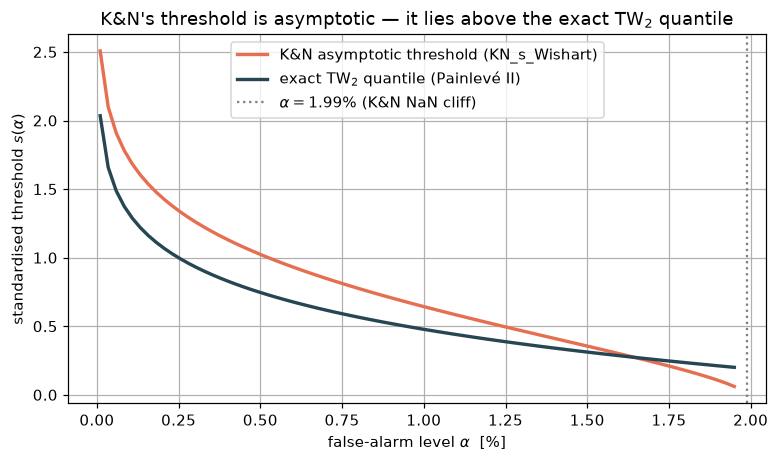

In [6]:
%matplotlib inline

logger.section("2. Asymptotic threshold vs the exact TW2 quantile")

alphas    = np.linspace(0.01, 1.95, 80)
kn_thr    = np.array([KN_s_Wishart(a, 2) for a in alphas])
exact_thr = np.array([tw2.ppf(1 - a/100) for a in alphas])

fig, ax = plt.subplots(figsize=(7.2, 4.3))
ax.plot(alphas, kn_thr,    color="#e76f51", lw=2.2, label="K&N asymptotic threshold (KN_s_Wishart)")
ax.plot(alphas, exact_thr, color="#264653", lw=2.2, label="exact TW$_2$ quantile (Painlevé II)")
ax.axvline(100/(16*np.pi), color="gray", ls=":", lw=1.5, label=r"$\alpha=1.99\%$ (K&N NaN cliff)")
ax.set_xlabel(r"false-alarm level $\alpha$  [%]")
ax.set_ylabel(r"standardised threshold $s(\alpha)$")
ax.set_title("K&N's threshold is asymptotic — it lies above the exact TW$_2$ quantile")
ax.legend(); fig.tight_layout()
save_figure(fig, filename="kn_threshold_vs_exact_tw2.png")

rel = (kn_thr - exact_thr) / exact_thr * 100
for a in [0.01, 0.1, 0.5, 1.0]:
    i = int(np.argmin(np.abs(alphas - a)))
    logger.info(
        f"  alpha={a:4.2f}%:  K&N s*={kn_thr[i]:.3f}  vs exact {exact_thr[i]:.3f}  "
        f"({rel[i]:+.1f}% higher)"
    )

## Piece 2 — the Johnstone centring/scaling constants

`KN_mu_sigma(n, p, beta)` returns the constants $\mu_{np}, \sigma_{np}$ that standardise the
largest eigenvalue. **Convention matters:** K&N calibrate them for the *unnormalised* Wishart
matrix $n\cdot S_n$ (not the sample covariance $S_n$), so `KN_rankEst` compares
$n\cdot\ell_k$ against $\hat\sigma^2(\mu_{np} + s\,\sigma_{np})$. This is a different
normalisation from `TracyWidomTW2.johnstone_params`, which is calibrated for the SCM as
returned by `np.cov` (divided by $K-1$). The two must not be mixed — a point the port's
docstring flags explicitly.

In [8]:
logger.section("3. Johnstone centring / scaling constants")

logger.info("Constants for the UNNORMALISED Wishart n*S (beta=2):")
logger.info(f"  {'n':>5} {'p':>4} {'mu_np':>12} {'sigma_np':>10}")
for (n, p) in [(400, 40), (400, 39), (120, 40), (60, 40)]:
    mu, sig = KN_mu_sigma(n, p, beta=2)
    logger.info(f"  {n:5d} {p:4d} {mu:12.3f} {sig:10.4f}")


=== 3. JOHNSTONE CENTRING / SCALING CONSTANTS
[18:49:03] [INFO]     Constants for the UNNORMALISED Wishart n*S (beta=2):
[18:49:03] [INFO]           n    p        mu_np   sigma_np
[18:49:03] [INFO]         400   40      692.974    15.6002
[18:49:03] [INFO]         400   39      688.791    15.6031
[18:49:03] [INFO]         120   40      298.558    10.8764
[18:49:03] [INFO]          60   40      197.974     9.2835


## Piece 3 — the self-consistent noise estimator (the heart of K&N)

This is what distinguishes K&N from naïve approaches, and it is the single most important
ingredient for the comparison in notebook 03.

**The problem.** With finite samples the signal and noise subspaces are not perfectly
orthogonal. The large signal eigenvalues *repel* the noise eigenvalues and absorb part of the
trace that "belongs" to the noise — the classic **eigenvalue repulsion**. So the naïve maximum-
likelihood estimate (the mean of the tail eigenvalues, once you assume $k$ signals) is
**biased low**. Worse, a plain trace estimate is biased *high*, because the strong spikes sit
inside the trace.

**K&N's fix.** Impose **trace conservation**: reintegrate the energy each spike stole from the
noise. The catch is circular — the correction depends on the unknown $\sigma^2$ — so K&N solve
it with a *self-consistent* fixed-point iteration, at each step taking the larger root of a
quadratic to recover each spike's bias-free contribution, until $\sigma^2$ converges.

The demo below plants **strong, well-separated** signals (population strengths $\ell=10,6,3$)
on top of unit noise and shows the three estimates side by side. Watch K&N recover the true
$\sigma^2 \approx 1$ *despite* the strong spikes, while the trace estimate inflates and the
naïve tail mean is depressed.

In [9]:
logger.section("4. The self-consistent noise estimator")

X   = helpers.make_spiked_data(K=400, W=40, spikes=(10.0, 6.0, 3.0), sigma2=1.0, seed=1)
res = helpers.eig_from_data(X)
ell, n = res["eigenvalues"], res["K"]

logger.info("true sigma^2                       = 1.000")
logger.info(
    f"trace(Sigma)/W                    = {res['sigma2_hat']:.3f}   "
    "<- inflated: 3 strong spikes leak into the trace"
)
logger.info(
    f"naive ML mean of tail (assume k=3) = {np.mean(ell[3:]):.3f}   "
    "<- depressed by eigenvalue repulsion"
)

logger.info("K&N self-consistent estimate KN_noiseEst(ell, n, kk):")
for kk in [1, 2, 3, 4]:
    logger.info(f"    kk={kk}:  sigma_hat^2 = {KN_noiseEst(ell, n, kk):.3f}")
logger.info("-> at the correct kk=3, K&N lands on ~1.0; the trace estimate is ~45% high.")


=== 4. THE SELF-CONSISTENT NOISE ESTIMATOR
[17:48:14] [INFO]     true sigma^2                       = 1.000
[17:48:14] [INFO]     trace(Sigma)/W                    = 1.452   <- inflated: 3 strong spikes leak into the trace
[17:48:14] [INFO]     naive ML mean of tail (assume k=3) = 0.971   <- depressed by eigenvalue repulsion
[17:48:14] [INFO]     K&N self-consistent estimate KN_noiseEst(ell, n, kk):
[17:48:14] [INFO]         kk=1:  sigma_hat^2 = 1.211
[17:48:14] [INFO]         kk=2:  sigma_hat^2 = 1.060
[17:48:14] [INFO]         kk=3:  sigma_hat^2 = 0.979
[17:48:14] [INFO]         kk=4:  sigma_hat^2 = 0.964
[17:48:14] [INFO]     -> at the correct kk=3, K&N lands on ~1.0; the trace estimate is ~45% high.


The iteration is not unconditionally safe: inside `KN_noiseEst` the quadratic can produce a
negative discriminant, in which case the loop stops early and keeps its current guess; and
`KN_rankEst` raises if a consistency check fails. On clean, well-separated data (as above) it
converges cleanly. On real data whose noise is not perfectly white/Gaussian, this per-step
nonlinear solve is where instabilities can enter — we return to that in notebook 03.

## Piece 4 — the sequential test `KN_rankEst`

Putting it together: for $k=1,2,\dots$, K&N re-estimates $\hat\sigma^2$ assuming $k$ signals,
standardises the $k$-th eigenvalue with the piece-2 constants for the reduced dimension, and
compares it against the piece-1 threshold. It stops at the first $k$ that fails, returning the
integer $\hat K = k-1$. Below, ground-truth rank recovery across a few planted configurations
($K=400$, $W=40$, $\gamma\approx0.10$).

In [10]:
logger.section("5. Ground-truth rank recovery")

logger.info("K=400, W=40, gamma~0.10, alpha=0.1%")
for spikes in [(), (5.0,), (8.0, 4.0), (10.0, 6.0, 3.0)]:
    ell = helpers.eig_from_data(helpers.make_spiked_data(400, 40, spikes, seed=2))["eigenvalues"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        K_hat, sig = KN_rankEst(ell, n=400, beta=2, alpha=0.1)

    hit = K_hat == len(spikes)
    msg = (f"  true rank = {len(spikes)}   ->   K&N K_hat = {K_hat}   "
           f"(sigma_hat^2={sig:.3f})   [{'ok' if hit else 'MISS'}]")
    logger.info(msg) if hit else logger.warning(msg)


=== 5. GROUND-TRUTH RANK RECOVERY
[17:57:27] [INFO]     K=400, W=40, gamma~0.10, alpha=0.1%
[17:57:27] [INFO]       true rank = 0   ->   K&N K_hat = 0   (sigma_hat^2=1.001)   [ok]
[17:57:27] [INFO]       true rank = 1   ->   K&N K_hat = 1   (sigma_hat^2=1.000)   [ok]
[17:57:27] [INFO]       true rank = 2   ->   K&N K_hat = 2   (sigma_hat^2=0.999)   [ok]
[17:57:27] [INFO]       true rank = 3   ->   K&N K_hat = 3   (sigma_hat^2=1.000)   [ok]


### Is K&N really "unstable at low $K$"?

A common claim is that K&N becomes unstable when realisations are few (aspect ratio
$\gamma \to 1$). It is worth checking rather than repeating. Below we drive $\gamma$ from 0.10
up to ~0.93 on a fixed true rank of 2, averaging over 20 noise realisations per point.

In [7]:
logger.section("6. Stability as gamma grows")

logger.info("true rank=2, spikes=(8,4), 20 seeds each")
logger.info(f"  {'K':>5} {'gamma':>7} {'mode':>6} {'mean':>7} {'std':>6}")
for K in [400, 120, 80, 60, 50, 44]:
    khs = []
    for s in range(20):
        ell = helpers.eig_from_data(
            helpers.make_spiked_data(K, 40, (8.0, 4.0), seed=s)
        )["eigenvalues"]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kh, _ = KN_rankEst(ell, n=K, beta=2, alpha=0.1)
        khs.append(kh)

    khs = np.array(khs)
    logger.info(
        f"  {K:5d} {40/(K-1):7.3f} {np.bincount(khs).argmax():6d} "
        f"{khs.mean():7.2f} {khs.std():6.2f}"
    )

logger.info("Notebook executed successfully. Figure saved to outputs/figures.")
logger.close()


=== 6. STABILITY AS GAMMA GROWS
[15:36:36] [INFO]     true rank=2, spikes=(8,4), 20 seeds each
[15:36:36] [INFO]           K   gamma   mode    mean    std
[15:36:36] [INFO]         400   0.100      2    2.00   0.00
[15:36:36] [INFO]         120   0.336      2    2.00   0.00
[15:36:36] [INFO]          80   0.506      2    2.00   0.00
[15:36:36] [INFO]          60   0.678      2    2.00   0.00
[15:36:36] [INFO]          50   0.816      2    2.00   0.00
[15:36:36] [INFO]          44   0.930      2    2.00   0.00
[15:36:36] [INFO]     Notebook executed successfully. Figure saved to outputs/figures.
Log closed: /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Kritchman_Nadler/outputs/logs/kritchman_nadler.log


On **clean Gaussian data K&N is remarkably stable** — it recovers rank 2 with zero variance
even at $\gamma\approx0.93$. So "unstable at low $\gamma$" is not the right summary. The
over-counting seen on some *real* calibrator data (e.g. a $\hat K$ of 21 on J1939-6342) comes
from the data violating the white-Gaussian noise model — coloured noise and near-threshold
structure that make the per-step self-consistent solve cascade — not from a high aspect ratio
per se. Notebook 03 shows this on the real MeerKAT stamps.

## Honest summary of Kritchman & Nadler

**Strengths**

- Rigorous, non-parametric, and — when its iteration converges — its **self-consistent noise
  estimator is genuinely excellent**, removing the spike-induced bias that inflates a plain
  trace estimate. This is a real advantage over our method with many strong signals (notebook 03).
- On clean data it is stable across a wide range of $\gamma$, contrary to the common claim.
- A single, familiar tuning knob ($\alpha$).

**Limitations**

- The TW threshold is **asymptotic**, valid only for small $\alpha$, with a hard **`α < 1.99%`
  NaN cliff** for complex data. It also sits above the exact quantile, making the effective
  operating point more conservative than the nominal $\alpha$.
- Each step re-solves a **nonlinear system**; on real, non-ideal noise this can cascade into
  **rank over-estimation**.
- The output is a bare **integer** — no measure of how marginal or how emphatic each detection
  is.

Notebook 02 builds an estimator that keeps K&N's sound sequential skeleton but swaps the
asymptotic tail for an exact one, trades the per-step nonlinear solve for a single fixed noise
estimate, and returns a continuous posterior instead of an integer — with its own, different
trade-offs.